In [1]:
import numpy as np
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
from numba import njit
from matplotlib.colors import ListedColormap

In [8]:
# GLOBAL STYLE SETTINGS (run once)

plt.rcParams.update({

    # --- FONT SIZES ---
    "font.size": 24,              # base font size
    "axes.titlesize": 20,         # title
    "axes.labelsize": 36,         # x/y labels
    "xtick.labelsize": 36,
    "ytick.labelsize": 36,
    "legend.fontsize": 16,

    # --- LINES ---
    "lines.linewidth": 5,
    "lines.markersize": 16,

    # --- FIGURE / AXIS ---
    "figure.figsize": (8, 6),
    "figure.dpi": 120,
    "axes.linewidth": 1.5,        # thicker axis spines

    # --- TICKS ---
    "xtick.major.size": 15,
    "xtick.major.width": 3,
    "ytick.major.size": 15,
    "ytick.major.width": 3,

    # --- LEGEND ---
    "legend.frameon": True,
    "legend.framealpha": 0.8,
    "legend.fancybox": True,

    # --- GRID (optional) ---
    #"axes.grid": True,
    #"grid.alpha": 0.3,
})


In [2]:


@njit
def pop_numba(nux, nuy, taux,s=1, dt=0.001, steps=10**5):
    delayx = int(taux / dt)
    X0 = np.array([0.6, 0.4], dtype=np.float64)
    Y0 = np.array([0.6, 0.4], dtype=np.float64)

    # Pre-allocate X_hist as a 2D array (delayx x 2)
    X_hist = np.zeros((delayx, 2), dtype=np.float64)
    for i in range(delayx):
        X_hist[i, :] = X0.copy()

    X = np.zeros((steps, 2), dtype=np.float64)
    Y = np.zeros((steps, 2), dtype=np.float64)

    for k in range(steps):
        x_tau = X_hist[0, :]
        y = Y0.copy()

        # Compute dx
        dx0 = X0[0] * y[0] - nux / 2 * X0[0] + nux / 2 * X0[1]
        dx1 = X0[1] * y[1] - nux / 2 * X0[1] + nux / 2 * X0[0]
        dx = np.array([dx0, dx1])

        # Compute dy
        dy0 = x_tau[1] * Y0[0] - nuy / 2 * Y0[0] + nuy / 2 * Y0[1]
        dy1 = s*x_tau[0] * Y0[1] - nuy / 2 * Y0[1] + nuy / 2 * Y0[0]
        dy = np.array([dy0, dy1])

        # Update X0 and Y0
        X0 += dt * dx
        norm_X0 = X0[0] + X0[1] + 1e-16
        X0 /= norm_X0

        Y0 += dt * dy
        norm_Y0 = Y0[0] + Y0[1] + 1e-16
        Y0 /= norm_Y0

        # Update X_hist (shift and append)
        for i in range(delayx - 1):
            X_hist[i, :] = X_hist[i + 1, :]
        X_hist[delayx - 1, :] = X0.copy()

        # Store results
        X[k, :] = X0
        Y[k, :] = Y0 

    # Return whether std of X[steps//2:, 0] > 0.01
    std_Y = np.std(Y[3*steps//4:, 0])

    return std_Y > 0.05 #check if observe oscillations by computing standard deviation of Y

# Parameters
NU = np.logspace(-2, 1, 20)
TAU = np.logspace(-1, 2, 20)
dt = 2e-3
s=0.5

# Prepare arguments for parallel execution
args = [(nux, nux, taux, s,dt, max(int(10 / nux/dt), int(taux / dt * 10))) for nux in NU for taux in TAU] #nux=nuy=nu

# Run in parallel
results = Parallel(n_jobs=-1)(delayed(pop_numba)(*arg) for arg in args)

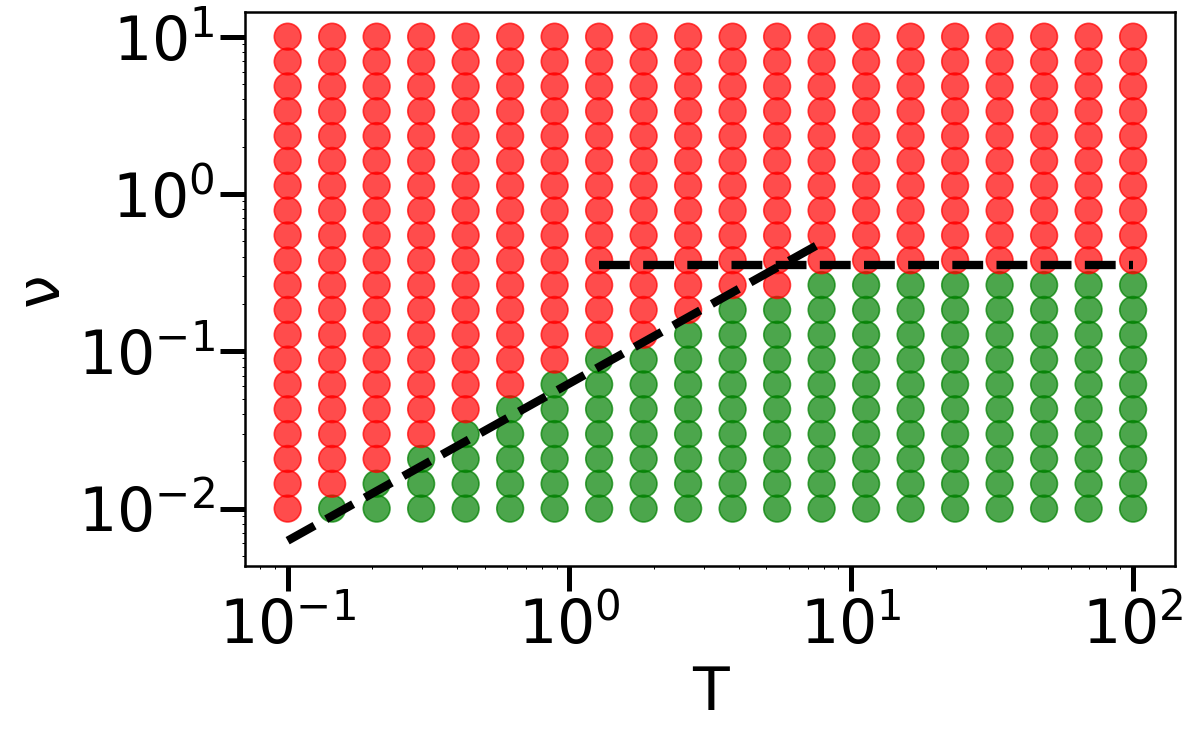

In [10]:
# Reshape results to match (NU, TAU) grid



cmap = ListedColormap(['red', 'green'])

Z = np.array(results).reshape(len(NU), len(TAU))
X, Y = np.meshgrid(TAU, NU)

# Plot
plt.figure(figsize=(10, 6))
plt.scatter(X.flatten(), Y.flatten(), c=Z.flatten(), cmap=cmap, alpha=0.7)
plt.xscale('log')
plt.yscale('log')
plt.xlabel('T')
plt.ylabel('ν')

x=np.unique(X)
plt.plot(x[x<10],np.array(x[x<10])*s/8,'--k')
plt.plot(x[x>1],np.ones(len(x[x>1]))/2*np.sqrt(s),'--k')
plt.savefig('2_pop_DGR.svg')

In [10]:
# Parameters
NU = np.logspace(-2, 1, 20)
TAU = np.logspace(-1, 2, 20)
dt = 1e-2
s=1/2

# Prepare arguments for parallel execution
args = [(nux, 0, taux, s,dt, max(int(10 / nux/dt), int(taux / dt * 10))) for nux in NU for taux in TAU] #nuy=0

# Run in parallel
results = Parallel(n_jobs=-1)(delayed(pop_numba)(*arg) for arg in args)

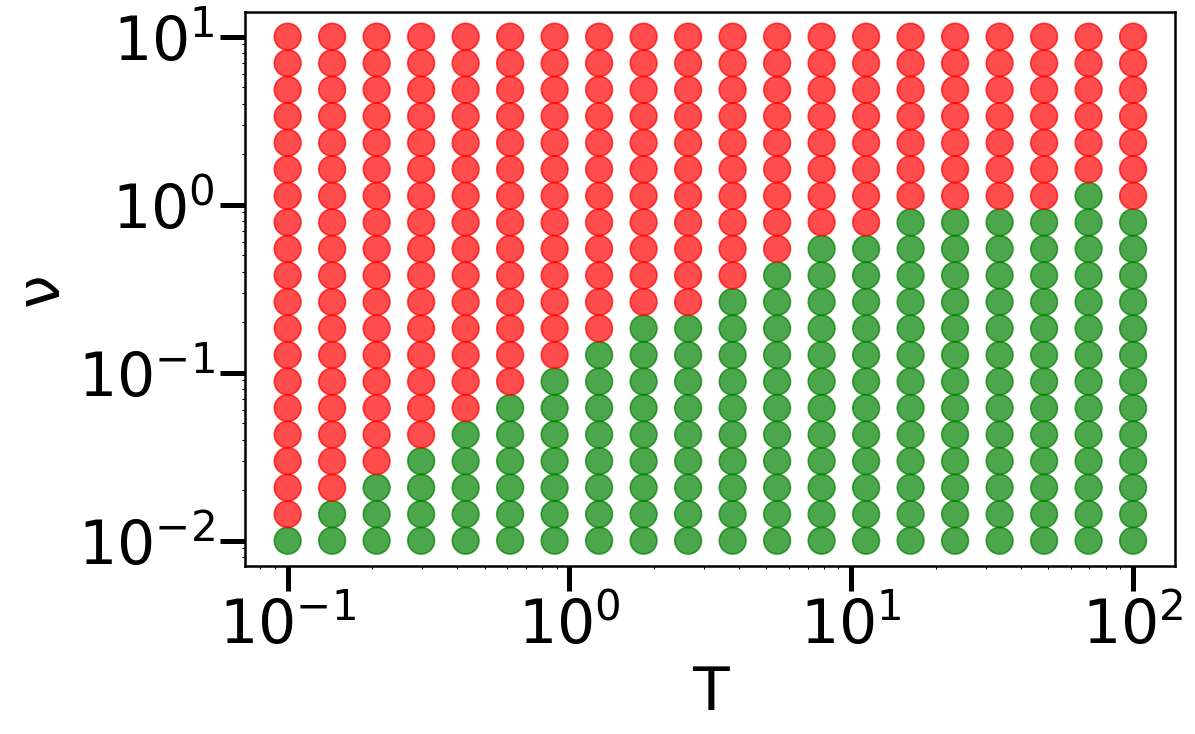

In [11]:
# Reshape results to match (NU, TAU) grid
Z = np.array(results).reshape(len(NU), len(TAU))
X, Y = np.meshgrid(TAU, NU)

# Plot
cmap = ListedColormap(['red', 'green'])
plt.figure(figsize=(10, 6))
plt.scatter(X.flatten(), Y.flatten(), c=Z.flatten(), cmap=cmap, alpha=0.7)
plt.xscale('log')
plt.yscale('log')
plt.xlabel('T')
plt.ylabel('ν')
plt.savefig('2_pop_one_DGR.svg')
#x=np.unique(X)
#plt.plot(x,np.array(x)*s/4,'--k')
#plt.plot(x,np.array(x)*s/2/np.pi,'--k')
